# Estimasi Usia Wajah dengan MobileNetV3-Small untuk *Age-Gating*

Notebook ini menjalankan rancangan pada proposal (Bab 2): audit UTKFace, *split* 70/15/15 berbasis kelompok duplikat, baseline **B0**, **B1**, **M1**, **B1 control**, evaluasi MAE dan *Challenge-T* (FPR/FNR, AUC), *bootstrap* berpasangan, biaya komputasi, analisis galat, dan demo inferensi.

**Cara pakai**
1. `Runtime > Change runtime type > T4 GPU`, lalu jalankan sel dari atas ke bawah.
2. Hasil permanen (arsip data, *manifest*, *checkpoint*, metrik, gambar) disimpan di Google Drive pada `CFG['PROJECT_DIR']`. Dataset diekstrak ke disk sementara Colab.
3. Tahap yang sudah selesai dipakai ulang otomatis. Pelatihan yang terputus tidak dilanjutkan; ganti `CFG['RUN_TAG']` lalu ulangi.
4. **Data uji terkunci** (`TEST_UNLOCKED = False`). Pilih konfigurasi dan ambang T dari validasi dulu, baru buka data uji di bagian 6.

**Privasi:** foto unggahan pada demo hanya diproses di *runtime* dan tidak disalin ke Drive, tetapi gambar ikut tersimpan di *output* sel. Kosongkan *output* (`Edit > Clear all outputs`) sebelum notebook dibagikan.

In [1]:
# @cell: setup
import os, sys, re, io, json, time, glob, shutil, hashlib, random, zipfile, platform, subprocess, datetime, functools
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torchvision
from torchvision import models, transforms as T
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import roc_auc_score

IN_COLAB = 'google.colab' in sys.modules
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
pd.set_option('display.precision', 3)
print('Colab:', IN_COLAB, '| device:', DEVICE, '| torch', torch.__version__, '| torchvision', torchvision.__version__)
if DEVICE.type != 'cuda':
    print('PERINGATAN: GPU tidak aktif. Pelatihan di CPU akan sangat lambat.')

Colab: True | device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130


## 0. Konfigurasi
Nilai mengikuti proposal: Bagian 2.1 (data dan *split*), Tabel 2 (pelatihan), dan Bagian 2.3 (evaluasi). Ubah di sini saja agar seluruh tahap konsisten.

In [2]:
# @cell: config
CFG = {
    # Lokasi
    'PROJECT_DIR': '/content/drive/MyDrive/age_gating_mnv3s',  # hasil permanen di Drive
    'LOCAL_DATA_DIR': '/content/utkface',                       # disk sementara Colab
    'KAGGLE_DATASET': 'moritzm00/utkface-cropped',
    'KAGGLE_URL': 'https://www.kaggle.com/datasets/moritzm00/utkface-cropped',
    'SAVE_ARCHIVE_TO_DRIVE': True,
    # Data dan split (Bagian 2.1)
    'AGE_RANGE': (0, 116),
    'AGE_BINS': [(0, 12), (13, 17), (18, 24), (25, 39), (40, 59), (60, 116)],
    'SPLIT_FRAC': {'train': 0.70, 'val': 0.15, 'test': 0.15},
    'SPLIT_SEED': 42,
    'DHASH_MERGE_MAX': 2,    # jarak Hamming dHash <= nilai ini: digabung sebagai near-duplicate
    'DHASH_REVIEW_MAX': 6,   # jarak (MERGE_MAX, REVIEW_MAX]: hanya ditampilkan untuk ditinjau
    # Praproses dan augmentasi (Bagian 2.2)
    'RESIZE': 256, 'CROP': 224,
    'MEAN': [0.485, 0.456, 0.406], 'STD': [0.229, 0.224, 0.225],
    'JITTER': 0.2,           # perubahan ringan kecerahan dan kontras (hanya data latih)
    # Pelatihan (Tabel 2)
    # Batch kecil = lebih banyak update. Batch 1024 (run r2) hanya ~16 langkah/epoch dan MAE val M1 naik 6.07 -> 6.72.
    # A100 dan T4 sama-sama muat batch 128; yang membatasi kecepatan adalah pemuatan data (NUM_WORKERS).
    'BATCH_SIZE': 128,
    'LR_HEAD': 3e-4, 'LR_BACKBONE': 1e-4, 'WEIGHT_DECAY': 1e-4,
    'SMOOTH_L1_BETA': 1.0,
    'MAX_EPOCHS': 60,        # T4: turunkan ke 40 bila runtime terbatas (~1 menit/epoch dengan 2-4 worker)
    'PATIENCE': 10,          # lebih longgar karena LR cosine masih turun di akhir pelatihan
    'WARMUP_EPOCHS': 2,      # LR naik linear selama warmup, lalu turun cosine sampai akhir MAX_EPOCHS
    'UNFREEZE_LAST': 13,     # M1 membuka seluruh backbone (features punya 13 modul); 3 = konfigurasi lama
    'M1_UPDATE_BN_STATS': True,   # True: statistik BatchNorm modul yang dibuka ikut diperbarui (aman untuk batch >= 32)
    'NUM_WORKERS': min(8, os.cpu_count() or 2),  # A100 Colab ~12 vCPU; T4 Colab hanya 2-4 vCPU
    'AMP': True,
    'SEEDS': [43],           # isi [42, 43, 44] bila runtime cukup untuk tiga seed
    'RUN_TAG': 'r3',         # ganti (mis. 'r4') bila pelatihan terputus atau konfigurasi diubah
    'RUN_BALANCED_SAMPLING': False,  # eksperimen tambahan: sampling per kelompok usia (M1bal)
    # Evaluasi (Bagian 2.3)
    'L_LIST': [18, 21], 'T_OFFSETS': [0, 3, 5],
    'T_SEARCH_MAX_OFFSET': 15,
    'FPR_TARGET': 0.05,      # aturan T rekomendasi: T terkecil dengan FPR validasi <= target
    'N_BOOT': 1000, 'CI': 0.95,
    'LAT_WARMUP': 50, 'LAT_RUNS': 2000, 'LAT_PREPROC_RUNS': 300,
    # Ukuran keberhasilan (Bagian 1.6)
    'MAE_REDUCTION_TARGET': 0.50, 'LAT_TARGET_MS': 30.0,
}
METHOD_NAMES = {'B0': 'B0 (median)', 'B1': 'B1 (beku)', 'M1': 'M1 (fine-tuning)',
                'B1c': 'B1 control', 'M1bal': 'M1 + sampling seimbang'}
GENDER = {0: 'laki-laki', 1: 'perempuan'}
RACE = {0: 'White', 1: 'Black', 2: 'Asian', 3: 'Indian', 4: 'Others'}
BIN_LABELS = [f'{lo}-{hi}' if hi < CFG['AGE_RANGE'][1] else f'{lo}+' for lo, hi in CFG['AGE_BINS']]

def age_bin(a):
    for (lo, hi), lab in zip(CFG['AGE_BINS'], BIN_LABELS):
        if lo <= a <= hi:
            return lab
    raise ValueError(a)

def now_utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')


In [3]:
# @cell: mount
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
PROJECT = Path(CFG['PROJECT_DIR'])
DIRS = {k: PROJECT / k for k in ['data', 'manifest', 'runs', 'results', 'figures']}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
(DIRS['results'] / 'preds').mkdir(exist_ok=True)
LOCAL = Path(CFG['LOCAL_DATA_DIR'])
print('Proyek:', PROJECT)

Mounted at /content/drive
Proyek: /content/drive/MyDrive/age_gating_mnv3s


In [4]:
# @cell: env
def env_info():
    info = {'time_utc': now_utc(), 'python': platform.python_version(), 'torch': torch.__version__,
            'torchvision': torchvision.__version__, 'numpy': np.__version__, 'cuda': torch.version.cuda,
            'cudnn': torch.backends.cudnn.version(), 'device': str(DEVICE),
            'cpu_threads': torch.get_num_threads(), 'cpu': platform.processor() or platform.machine()}
    try:
        out = subprocess.run(['lscpu'], capture_output=True, text=True).stdout
        name = [l.split(':', 1)[1].strip() for l in out.splitlines() if l.startswith('Model name')]
        info['cpu'] = name[0] if name else info['cpu']
    except Exception:
        pass
    if torch.cuda.is_available():
        prop = torch.cuda.get_device_properties(0)
        info.update(gpu=prop.name, gpu_mem_gb=round(prop.total_memory / 1e9, 1))
    return info

ENV = env_info()
print(json.dumps(ENV, indent=1))
json.dump(ENV, open(DIRS['results'] / f"env_{ENV['time_utc'].replace(':', '')}.json", 'w'), indent=1)

{
 "time_utc": "2026-10-12T12:44:12+00:00",
 "python": "3.13.15",
 "torch": "2.11.0+cu130",
 "torchvision": "0.26.0+cu130",
 "numpy": "2.1.3",
 "cuda": "13.0",
 "cudnn": 92700,
 "device": "cuda",
 "cpu_threads": 4,
 "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
 "gpu": "Tesla T4",
 "gpu_mem_gb": 15.6
}


## 1. Akuisisi data
Sumber: salinan Kaggle UTKFace *aligned and cropped* (proposal [9]). Unduhan pertama disimpan sebagai arsip zip di Drive beserta URL, versi, tanggal, dan SHA-256, sehingga sesi berikutnya cukup mengekstrak arsip itu. Bila Kaggle meminta login, isi `KAGGLE_USERNAME` dan `KAGGLE_KEY` di **Colab Secrets** (ikon kunci di panel kiri).

In [5]:
# @cell: acquire
ARCHIVE = DIRS['data'] / 'utkface_cropped.zip'
SOURCE_JSON = DIRS['data'] / 'source.json'

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

if not (LOCAL / '.ready').exists():
    LOCAL.mkdir(parents=True, exist_ok=True)
    if ARCHIVE.exists():
        print('Ekstrak arsip dari Drive:', ARCHIVE)
        with zipfile.ZipFile(ARCHIVE) as z:
            z.extractall(LOCAL)
    else:
        if IN_COLAB:
            try:
                from google.colab import userdata
                for k in ['KAGGLE_USERNAME', 'KAGGLE_KEY']:
                    v = userdata.get(k)
                    if v:
                        os.environ.setdefault(k, v)
            except Exception:
                pass  # dataset publik biasanya bisa diunduh tanpa login
        try:
            import kagglehub
        except ImportError:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'], check=True)
            import kagglehub
        try:
            src = Path(kagglehub.dataset_download(CFG['KAGGLE_DATASET']))
        except Exception as e:
            raise RuntimeError('Unduhan Kaggle gagal. Isi KAGGLE_USERNAME dan KAGGLE_KEY di Colab Secrets, '
                               'lalu jalankan ulang sel ini.') from e
        shutil.copytree(src, LOCAL, dirs_exist_ok=True)
        source = {'kaggle_dataset': CFG['KAGGLE_DATASET'], 'url': CFG['KAGGLE_URL'],
                  'kagglehub_path': str(src),
                  'version': src.name if src.parent.name == 'versions' else 'tidak diketahui',
                  'downloaded_utc': now_utc()}
        if CFG['SAVE_ARCHIVE_TO_DRIVE']:
            tmp = shutil.make_archive(str(LOCAL.parent / '_utkface_tmp'), 'zip', LOCAL)
            shutil.move(tmp, ARCHIVE)
            source['archive'] = str(ARCHIVE)
            source['archive_sha256'] = sha256_file(ARCHIVE)
        json.dump(source, open(SOURCE_JSON, 'w'), indent=1)
    (LOCAL / '.ready').touch()

SOURCE = json.load(open(SOURCE_JSON)) if SOURCE_JSON.exists() else {}
IMG_FILES = sorted(p for p in LOCAL.rglob('*')
                   if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
                   and not p.name.startswith('.') and '__MACOSX' not in p.parts)
SOURCE['n_files_found'] = len(IMG_FILES)
print(json.dumps(SOURCE, indent=1))

Using Colab cache for faster access to the 'utkface-cropped' dataset.
{
 "kaggle_dataset": "moritzm00/utkface-cropped",
 "url": "https://www.kaggle.com/datasets/moritzm00/utkface-cropped",
 "kagglehub_path": "/kaggle/input/utkface-cropped",
 "version": "tidak diketahui",
 "downloaded_utc": "2026-10-12T12:45:51+00:00",
 "archive": "/content/drive/MyDrive/age_gating_mnv3s/data/utkface_cropped.zip",
 "archive_sha256": "7c692b6d9b1c5dad000053e95328e8b7d102f2a7cfb2e1d5ae904ddc2208ae41",
 "n_files_found": 23708
}


## 2. Audit data dan *manifest*
Sesuai Bagian 2.1:
- label dibaca dari nama berkas `[usia]_[jenis kelamin]_[ras]_[waktu]`; format salah atau kode di luar rentang dikeluarkan dengan alasan;
- citra rusak dikeluarkan;
- duplikat identik dicari dengan *hash* berkas (SHA-256) dan *hash* piksel. Kelompok dengan label usia sama disimpan satu; kelompok dengan label usia berbeda dikeluarkan seluruhnya;
- kemiripan visual dicari dengan dHash 64-bit. Pasangan dengan jarak `<= DHASH_MERGE_MAX` digabung dalam satu grup sehingga selalu berada pada *split* yang sama. Pasangan sampai `DHASH_REVIEW_MAX` hanya ditampilkan untuk ditinjau;
- *split* 70/15/15 berstrata enam kelompok usia, dibagi per grup dengan `SPLIT_SEED` tetap.

*Manifest* disimpan di Drive dan dipakai ulang. Untuk membangun ulang (mis. setelah mengubah ambang dHash), hapus `manifest/manifest.csv` **sebelum** pelatihan.

In [6]:
# @cell: audit
MANIFEST = DIRS['manifest'] / 'manifest.csv'
LABEL_RE = re.compile(r'^(\d+)_(\d+)_(\d+)_(\d+)')
_POP8 = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def parse_label(name):
    m = LABEL_RE.match(name)
    if not m:
        return None, 'format nama berkas tidak sesuai'
    age, gender, race = int(m.group(1)), int(m.group(2)), int(m.group(3))
    lo, hi = CFG['AGE_RANGE']
    if not lo <= age <= hi:
        return None, f'usia di luar rentang {lo}-{hi}'
    if gender not in GENDER:
        return None, 'kode jenis kelamin tidak valid'
    if race not in RACE:
        return None, 'kode ras tidak valid'
    return (age, gender, race), None

def dhash64(img):
    g = np.asarray(img.convert('L').resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return int.from_bytes(np.packbits((g[:, 1:] > g[:, :-1]).ravel()).tobytes(), 'big')

def inspect(path):
    rec = {'path': str(path.relative_to(LOCAL)), 'name': path.name}
    try:
        raw = path.read_bytes()
        rec['sha256'] = hashlib.sha256(raw).hexdigest()
        with Image.open(io.BytesIO(raw)) as im:
            im.load()
            rec['mode'] = im.mode
            rgb = im.convert('RGB')
        arr = np.asarray(rgb)
        rec.update(width=rgb.width, height=rgb.height,
                   pix_md5=hashlib.md5(arr.tobytes() + str(arr.shape).encode()).hexdigest(),
                   dhash=dhash64(rgb))
    except Exception as e:
        rec['reason'] = f'citra rusak atau tidak terbaca ({type(e).__name__})'
        return rec
    lab, why = parse_label(path.name)
    if lab is None:
        rec['reason'] = why
    else:
        rec.update(age=lab[0], gender=lab[1], race=lab[2])
    return rec

class DSU:
    def __init__(self, n): self.p = list(range(n))
    def find(self, i):
        while self.p[i] != i:
            self.p[i] = self.p[self.p[i]]; i = self.p[i]
        return i
    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b: self.p[max(a, b)] = min(a, b)

def popcount64(x):
    if hasattr(np, 'bitwise_count'):
        return np.bitwise_count(x)
    return _POP8[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1)

def near_pairs(hashes, max_d, block=512):
    h = np.asarray(hashes, dtype=np.uint64)
    out = []
    for s in range(0, len(h), block):
        d = popcount64(h[s:s + block, None] ^ h[None, :])
        i, j = np.nonzero(d <= max_d)
        keep = j > i + s
        i, j = i[keep], j[keep]
        out.append(np.stack([i + s, j, d[i, j]], 1))
    return np.concatenate(out).astype(int) if out else np.zeros((0, 3), int)

def group_split(groups, frac, seed):
    """Alokasi grup per strata ke split dengan defisit terbesar terhadap target proporsi."""
    rng = np.random.default_rng(seed)
    assign = {}
    for _, g in groups.groupby('stratum', sort=True):
        gids = g['group'].to_numpy().copy()
        size = dict(zip(g['group'], g['size']))
        rng.shuffle(gids)
        total = g['size'].sum()
        filled = {k: 0 for k in frac}
        for gid in gids:
            k = max(frac, key=lambda s: frac[s] * total - filled[s])
            assign[gid] = k
            filled[k] += size[gid]
    return assign

if MANIFEST.exists():
    print('Manifest sudah ada, dipakai ulang:', MANIFEST)
else:
    t0 = time.time()
    with ThreadPoolExecutor(8) as ex:
        recs = list(ex.map(inspect, IMG_FILES))
    audit = pd.DataFrame(recs)
    if 'reason' not in audit:
        audit['reason'] = np.nan
    print(f'Audit {len(audit)} berkas selesai dalam {time.time() - t0:.0f} s')

    excluded = [audit[audit.reason.notna()]]
    valid = audit[audit.reason.isna()].sort_values('path').reset_index(drop=True)
    valid[['age', 'gender', 'race', 'width', 'height']] = valid[['age', 'gender', 'race', 'width', 'height']].astype(int)

    # Duplikat identik (hash berkas atau hash piksel)
    dsu = DSU(len(valid))
    for key in ['sha256', 'pix_md5']:
        for idx in valid.groupby(key).indices.values():
            for j in idx[1:]:
                dsu.union(idx[0], j)
    valid['exact_group'] = [dsu.find(i) for i in range(len(valid))]
    drop_reason = pd.Series(np.nan, index=valid.index, dtype=object)
    for _, g in valid.groupby('exact_group'):
        if len(g) == 1:
            continue
        if g.age.nunique() == 1:
            drop_reason[g.index[1:]] = 'duplikat identik (disimpan satu)'
        else:
            drop_reason[g.index] = 'duplikat identik dengan label usia berbeda'
    valid['reason'] = drop_reason
    excluded.append(valid[valid.reason.notna()])
    kept = valid[valid.reason.isna()].drop(columns=['reason', 'exact_group']).reset_index(drop=True)

    # Near-duplicate dengan dHash
    pairs = near_pairs(kept.dhash.tolist(), CFG['DHASH_REVIEW_MAX'])
    dsu = DSU(len(kept))
    for i, j, d in pairs:
        if d <= CFG['DHASH_MERGE_MAX']:
            dsu.union(i, j)
    kept['group'] = [dsu.find(i) for i in range(len(kept))]
    near = pd.DataFrame({'path_a': kept.path.values[pairs[:, 0]] if len(pairs) else [],
                         'path_b': kept.path.values[pairs[:, 1]] if len(pairs) else [],
                         'age_a': kept.age.values[pairs[:, 0]] if len(pairs) else [],
                         'age_b': kept.age.values[pairs[:, 1]] if len(pairs) else [],
                         'dhash_dist': pairs[:, 2] if len(pairs) else []})
    near['action'] = np.where(near.dhash_dist <= CFG['DHASH_MERGE_MAX'], 'digabung (satu split)', 'tinjau saja')
    near.to_csv(DIRS['manifest'] / 'near_pairs.csv', index=False)

    # Split berstrata per grup
    kept['age_bin'] = kept.age.map(age_bin)
    groups = kept.groupby('group').agg(size=('path', 'size'), med_age=('age', 'median')).reset_index()
    groups['stratum'] = groups.med_age.map(lambda a: age_bin(int(round(a))))
    assign = group_split(groups, CFG['SPLIT_FRAC'], CFG['SPLIT_SEED'])
    kept['split'] = kept.group.map(assign)

    cols = ['path', 'age', 'gender', 'race', 'age_bin', 'group', 'split', 'width', 'height', 'mode', 'sha256', 'dhash']
    kept[cols].to_csv(MANIFEST, index=False)
    exc = pd.concat(excluded)[['path', 'reason']]
    exc.to_csv(DIRS['manifest'] / 'excluded.csv', index=False)
    meta = {'created_utc': now_utc(), 'source': SOURCE, 'n_files': len(audit), 'n_kept': len(kept),
            'n_excluded': len(exc), 'excluded_by_reason': exc.reason.value_counts().to_dict(),
            'n_groups': int(kept.group.nunique()), 'n_near_pairs_merged': int((near.dhash_dist <= CFG['DHASH_MERGE_MAX']).sum()),
            'n_near_pairs_review': int((near.dhash_dist > CFG['DHASH_MERGE_MAX']).sum()),
            'split_counts': kept.split.value_counts().to_dict(), 'split_seed': CFG['SPLIT_SEED'],
            'config': {k: CFG[k] for k in ['AGE_RANGE', 'AGE_BINS', 'SPLIT_FRAC', 'DHASH_MERGE_MAX', 'DHASH_REVIEW_MAX']}}
    json.dump(meta, open(DIRS['manifest'] / 'meta.json', 'w'), indent=1, default=str)
    print('Manifest dibuat:', MANIFEST)

MAN = pd.read_csv(MANIFEST)
MANIFEST_SHA = sha256_file(MANIFEST)
META = json.load(open(DIRS['manifest'] / 'meta.json'))
print(json.dumps({k: META[k] for k in ['n_files', 'n_kept', 'n_excluded', 'excluded_by_reason', 'n_groups',
                                       'n_near_pairs_merged', 'n_near_pairs_review', 'split_counts']}, indent=1))
print('SHA-256 manifest:', MANIFEST_SHA)

Audit 23708 berkas selesai dalam 19 s
Manifest dibuat: /content/drive/MyDrive/age_gating_mnv3s/manifest/manifest.csv
{
 "n_files": 23708,
 "n_kept": 23110,
 "n_excluded": 598,
 "excluded_by_reason": {
  "duplikat identik dengan label usia berbeda": 419,
  "duplikat identik (disimpan satu)": 176,
  "format nama berkas tidak sesuai": 3
 },
 "n_groups": 20829,
 "n_near_pairs_merged": 6612,
 "n_near_pairs_review": 394722,
 "split_counts": {
  "train": 16176,
  "val": 3468,
  "test": 3466
 }
}
SHA-256 manifest: 359e23008523d4649c7dd53e9b1771729e302b6a3b7c1d974e1917fe4aa55e9c


split,train,val,test,total
age_bin,,,,
0-12,2384,487,490,3361
13-17,566,112,109,787
18-24,1888,353,364,2605
25-39,6295,1516,1510,9321
40-59,3178,629,622,4429
60+,1865,371,371,2607
total,16176,3468,3466,23110


gender,laki-laki,perempuan
jenis kelamin,12067,11043


race,White,Black,Indian,Asian,Others
ras,9860,4418,3846,3375,1611


Ukuran citra terbanyak: {'200x200': 23110}


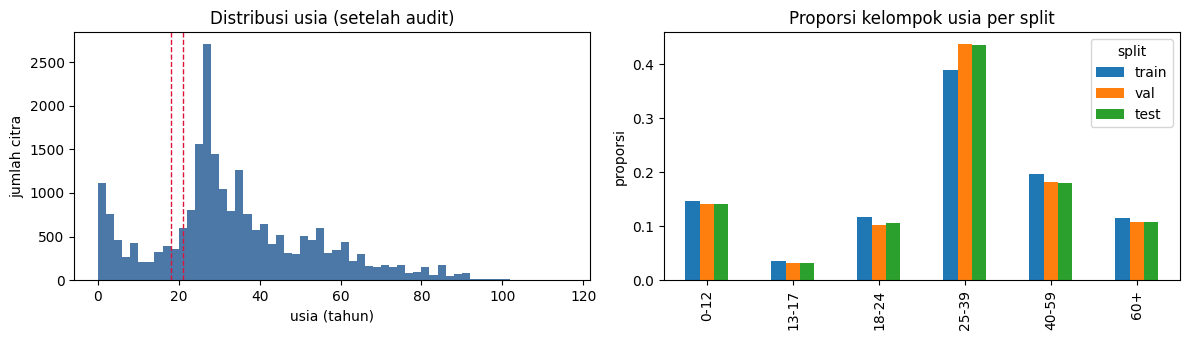

In [7]:
# @cell: audit_report
tab = pd.crosstab(MAN.age_bin, MAN.split).reindex(BIN_LABELS)[['train', 'val', 'test']]
tab['total'] = tab.sum(axis=1)
tab.loc['total'] = tab.sum()
display(tab)
display(pd.DataFrame({'jenis kelamin': MAN.gender.map(GENDER).value_counts(), }).T)
display(pd.DataFrame({'ras': MAN.race.map(RACE).value_counts()}).T)
print('Ukuran citra terbanyak:', (MAN.width.astype(str) + 'x' + MAN.height.astype(str)).value_counts().head(3).to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(MAN.age, bins=range(0, 118, 2), color='#4c78a8')
for L in CFG['L_LIST']:
    ax[0].axvline(L, color='crimson', ls='--', lw=1)
ax[0].set(title='Distribusi usia (setelah audit)', xlabel='usia (tahun)', ylabel='jumlah citra')
(tab.drop('total').drop(columns='total') / tab.drop('total')[['train', 'val', 'test']].sum()).plot.bar(ax=ax[1])
ax[1].set(title='Proporsi kelompok usia per split', xlabel='', ylabel='proporsi')
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'audit_distribusi.png', dpi=150); plt.show()

{'tinjau saja': 394722, 'digabung (satu split)': 6612}


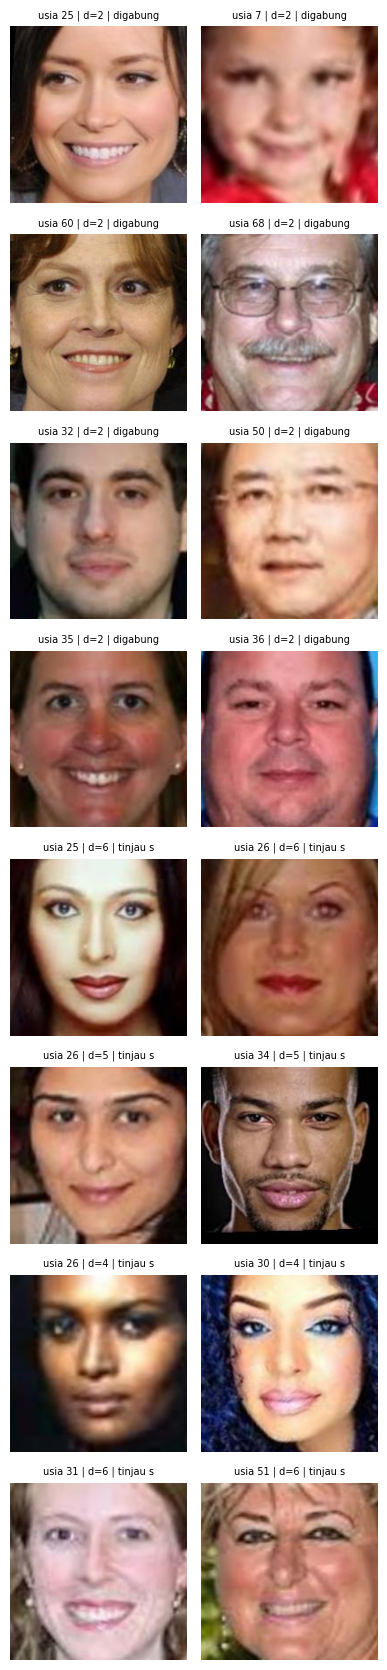

In [8]:
# @cell: near_review
# Tinjau pasangan mirip: dHash bukan pengenalan identitas. Jika pasangan "digabung" ternyata orang berbeda,
# turunkan DHASH_MERGE_MAX lalu bangun ulang manifest (hapus manifest.csv) sebelum pelatihan.
near = pd.read_csv(DIRS['manifest'] / 'near_pairs.csv')
print(near.action.value_counts().to_dict())
show = pd.concat([near[near.action.str.startswith('digabung')].sample(min(4, (near.action.str.startswith('digabung')).sum()), random_state=0),
                  near[near.action == 'tinjau saja'].sample(min(4, (near.action == 'tinjau saja').sum()), random_state=0)])
if len(show):
    fig, axes = plt.subplots(len(show), 2, figsize=(4, 2.1 * len(show)), squeeze=False)
    for r, (_, row) in enumerate(show.iterrows()):
        for c, key in enumerate(['a', 'b']):
            axes[r, c].imshow(Image.open(LOCAL / row[f'path_{key}']).convert('RGB'))
            axes[r, c].set_title(f"usia {row[f'age_{key}']} | d={row.dhash_dist} | {row.action[:8]}", fontsize=7)
            axes[r, c].axis('off')
    plt.tight_layout(); plt.show()
else:
    print('Tidak ada pasangan mirip pada ambang tinjauan.')

## 3. Praproses, contoh data, dan bukti kelayakan
Praproses sama untuk semua model: sisi pendek 256, *center crop* 224, normalisasi ImageNet. Augmentasi (pembalikan horizontal, kecerahan dan kontras ringan) hanya untuk data latih. Sel di bawah juga menghasilkan contoh data per kelompok usia dan menjalankan model pralatih satu *batch* sebagai bukti kelayakan.

In [9]:
# @cell: data
NORM = T.Normalize(CFG['MEAN'], CFG['STD'])
TF_EVAL = T.Compose([T.Resize(CFG['RESIZE']), T.CenterCrop(CFG['CROP']), T.ToTensor(), NORM])
TF_TRAIN = T.Compose([T.Resize(CFG['RESIZE']), T.CenterCrop(CFG['CROP']), T.RandomHorizontalFlip(),
                      T.ColorJitter(brightness=CFG['JITTER'], contrast=CFG['JITTER']), T.ToTensor(), NORM])

class FaceAge(Dataset):
    def __init__(self, df, tf):
        self.paths = [LOCAL / p for p in df.path]
        self.ages = df.age.to_numpy(dtype=np.float32)
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            x = self.tf(im.convert('RGB'))
        return x, self.ages[i]

def _worker_init(worker_id, base_seed):
    np.random.seed(base_seed + worker_id); random.seed(base_seed + worker_id)

def make_loader(df, tf, shuffle, seed, sampler=None, batch_size=None):
    g = torch.Generator(); g.manual_seed(seed)
    nw = CFG['NUM_WORKERS']
    return DataLoader(FaceAge(df, tf), batch_size=batch_size or CFG['BATCH_SIZE'],
                      shuffle=shuffle and sampler is None, sampler=sampler, num_workers=nw,
                      pin_memory=DEVICE.type == 'cuda', generator=g, persistent_workers=nw > 0,
                      worker_init_fn=functools.partial(_worker_init, base_seed=seed) if nw else None)

TR = MAN[MAN.split == 'train'].reset_index(drop=True)
VA = MAN[MAN.split == 'val'].reset_index(drop=True)
_TE = MAN[MAN.split == 'test'].reset_index(drop=True)
MEDIAN_AGE = float(np.median(TR.age))
print(f'train {len(TR)} | val {len(VA)} | test {len(_TE)} (terkunci) | median usia latih = {MEDIAN_AGE}')

train 16176 | val 3468 | test 3466 (terkunci) | median usia latih = 29.0


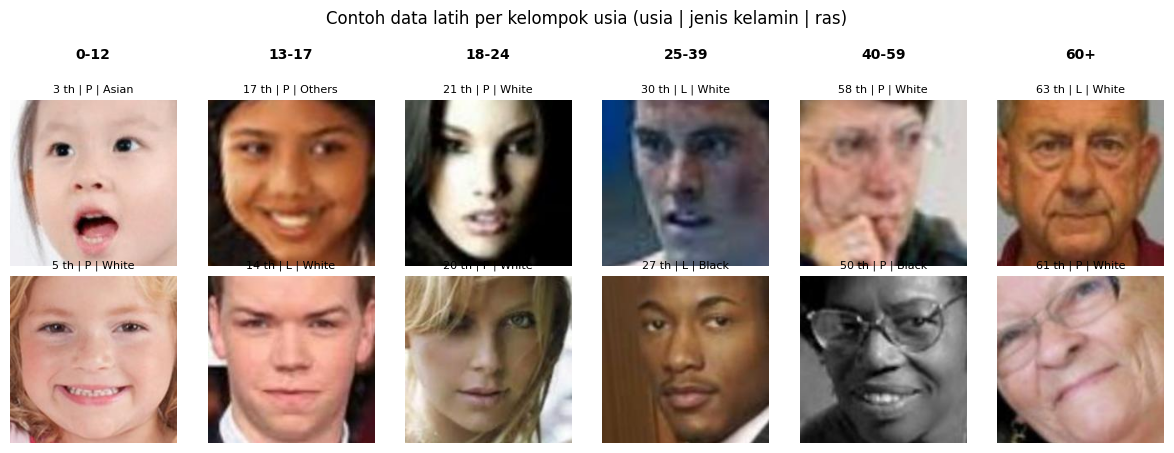

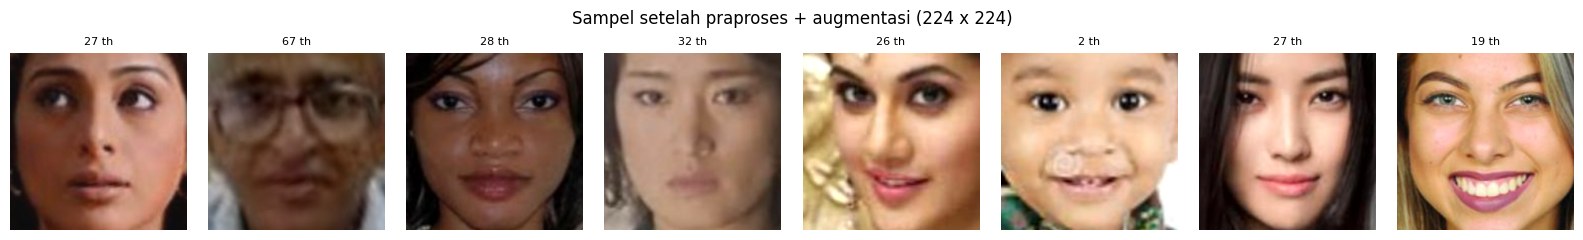

In [10]:
# @cell: examples
fig, axes = plt.subplots(2, len(BIN_LABELS), figsize=(2 * len(BIN_LABELS), 4.4))
for c, lab in enumerate(BIN_LABELS):
    sub = TR[TR.age_bin == lab].sample(min(2, (TR.age_bin == lab).sum()), random_state=c)
    for r in range(2):
        ax = axes[r, c]; ax.axis('off')
        if len(sub) > r:
            row = sub.iloc[r]
            ax.imshow(Image.open(LOCAL / row.path).convert('RGB'))
            ax.set_title(f"{row.age} th | {GENDER[row.gender][0].upper()} | {RACE[row.race]}", fontsize=8)
    axes[0, c].text(0.5, 1.25, lab, transform=axes[0, c].transAxes, ha='center', fontsize=10, weight='bold')
plt.suptitle('Contoh data latih per kelompok usia (usia | jenis kelamin | ras)', y=1.02)
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'contoh_data.png', dpi=150, bbox_inches='tight'); plt.show()

# Tinjau hasil praproses latih: wajah harus tetap terlihat setelah resize, crop, dan augmentasi
x, y = next(iter(make_loader(TR, TF_TRAIN, True, 0, batch_size=8)))
den = (x * torch.tensor(CFG['STD']).view(1, 3, 1, 1) + torch.tensor(CFG['MEAN']).view(1, 3, 1, 1)).clamp(0, 1)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for i, ax in enumerate(axes):
    ax.imshow(den[i].permute(1, 2, 0)); ax.set_title(f'{int(y[i])} th', fontsize=8); ax.axis('off')
plt.suptitle('Sampel setelah praproses + augmentasi (224 x 224)'); plt.tight_layout()
plt.savefig(DIRS['figures'] / 'praproses_latih.png', dpi=150); plt.show()

## 4. Model dan prosedur pelatihan
- **Model:** MobileNetV3-Small pralatih ImageNet (torchvision). `classifier[3]` diganti `Linear(1024, 1)`, bobot awal kecil, bias awal = median usia latih. Proyeksi fitur, Hardswish, dan *dropout* dipertahankan; tanpa softmax.
- **B1:** hanya `classifier` yang dilatih; *backbone* dan statistik BatchNorm beku.
- **M1:** mulai dari *checkpoint* B1 terbaik; seluruh `features` (`UNFREEZE_LAST = 13`) dan `classifier` dilatih (LR *backbone* 1e-4, *head* 3e-4). Statistik BatchNorm modul yang dibuka ikut diperbarui (`M1_UPDATE_BN_STATS = True`).
- **B1 control:** mulai dari *checkpoint* B1 yang sama; hanya `classifier` yang dilanjutkan, dengan konfigurasi dan *seed* yang sama dengan M1.
- Smooth L1 (beta 1), AdamW (*weight decay* 1e-4), *batch* 128, LR *warmup* linear 2 *epoch* lalu *cosine decay*, maks. 60 *epoch*, *early stopping* 10 *epoch* pada MAE validasi; *checkpoint* = MAE validasi terendah.

In [11]:
# @cell: model
def build_model(median_age, pretrained=True):
    w = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if pretrained else None
    m = models.mobilenet_v3_small(weights=w, progress=False)
    head = nn.Linear(m.classifier[3].in_features, 1)
    nn.init.normal_(head.weight, 0.0, 0.01)
    nn.init.constant_(head.bias, median_age)
    m.classifier[3] = head
    return m

def prepare(m, mode):
    """mode 'head' (B1, B1 control) atau 'finetune' (M1). Mengembalikan param group untuk AdamW."""
    for p in m.parameters():
        p.requires_grad = False
    head = list(m.classifier.parameters())
    for p in head:
        p.requires_grad = True
    groups = [{'params': head, 'lr': CFG['LR_HEAD']}]
    if mode == 'finetune':
        bb = [p for mod in m.features[-CFG['UNFREEZE_LAST']:] for p in mod.parameters()]
        for p in bb:
            p.requires_grad = True
        groups.append({'params': bb, 'lr': CFG['LR_BACKBONE']})
    return groups

def set_mode(m, mode):
    m.eval()                 # BatchNorm memakai statistik pralatih
    m.classifier.train()     # dropout aktif saat latih
    if mode == 'finetune' and CFG['M1_UPDATE_BN_STATS']:
        for mod in m.features[-CFG['UNFREEZE_LAST']:]:
            mod.train()      # opsional: statistik BatchNorm modul yang dibuka ikut diperbarui

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

@torch.inference_mode()
def predict(m, df):
    m.eval().to(DEVICE)
    out = []
    for x, _ in make_loader(df, TF_EVAL, False, 0, batch_size=128):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=CFG['AMP'] and DEVICE.type == 'cuda'):
            out.append(m(x.to(DEVICE, non_blocking=True)).float().squeeze(1).cpu())
    return torch.cat(out).numpy().astype(np.float64)

# Bukti kelayakan: model pralatih berjalan pada satu batch data nyata
_m = build_model(MEDIAN_AGE).to(DEVICE).eval()
_x, _y = next(iter(make_loader(VA, TF_EVAL, False, 0, batch_size=16)))
with torch.inference_mode():
    _p = _m(_x.to(DEVICE)).squeeze(1).cpu()
print('keluaran awal (seharusnya dekat median):', _p[:6].numpy().round(2), '| label:', _y[:6].numpy())
print(f"MAE validasi B0 (median {MEDIAN_AGE}): {np.mean(np.abs(VA.age - MEDIAN_AGE)):.2f} tahun")
del _m

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth
keluaran awal (seharusnya dekat median): [28.72 28.71 28.79 28.86 29.02 28.84] | label: [100. 101. 105. 105.  10.  10.]
MAE validasi B0 (median 29.0): 14.41 tahun


In [12]:
# @cell: train_fn
def run_dir(method, seed):
    return DIRS['runs'] / f"{method}_s{seed}_{CFG['RUN_TAG']}"

def train_run(method, seed, mode, init_ckpt=None, sampler_weights=None):
    rd = run_dir(method, seed)
    if (rd / 'done.json').exists():
        old = json.load(open(rd / 'config.json')).get('manifest_sha256')
        if old != MANIFEST_SHA:
            raise RuntimeError(f'[{rd.name}] dilatih dengan manifest lain ({str(old)[:12]}...). '
                               f'Ganti CFG["RUN_TAG"] agar semua model dilatih ulang pada manifest sekarang.')
        print(f'[{rd.name}] sudah selesai, dipakai ulang:', json.load(open(rd / 'done.json')))
        return rd
    if rd.exists() and any(rd.iterdir()):
        raise RuntimeError(f'[{rd.name}] ada tetapi belum selesai (pelatihan terputus). '
                           f'Ganti CFG["RUN_TAG"] lalu jalankan ulang dari B1 agar M1 dan B1 control '
                           f'berasal dari checkpoint B1 yang sama.')
    rd.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    m = build_model(MEDIAN_AGE)
    if init_ckpt is not None:
        m.load_state_dict(torch.load(init_ckpt, map_location='cpu')['model'])
    groups = prepare(m, mode)
    m.to(DEVICE)
    opt = torch.optim.AdamW(groups, weight_decay=CFG['WEIGHT_DECAY'])
    loss_fn = nn.SmoothL1Loss(beta=CFG['SMOOTH_L1_BETA'])
    use_amp = CFG['AMP'] and DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    sampler = None
    if sampler_weights is not None:
        g = torch.Generator(); g.manual_seed(seed)
        sampler = WeightedRandomSampler(torch.as_tensor(sampler_weights, dtype=torch.double),
                                        num_samples=len(sampler_weights), replacement=True, generator=g)
    dl = make_loader(TR, TF_TRAIN, True, seed, sampler)
    total_steps = CFG['MAX_EPOCHS'] * len(dl)
    warmup_steps = max(1, CFG['WARMUP_EPOCHS'] * len(dl))
    def lr_factor(step):
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        t = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.01 + 0.99 * 0.5 * (1 + np.cos(np.pi * min(1.0, t)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
    n_train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    json.dump({'method': method, 'seed': seed, 'mode': mode, 'init_ckpt': str(init_ckpt) if init_ckpt else None,
               'trainable_params': n_train, 'median_age': MEDIAN_AGE, 'manifest_sha256': MANIFEST_SHA,
               'started_utc': now_utc(), 'env': ENV,
               'cfg': {k: CFG[k] for k in ['BATCH_SIZE', 'LR_HEAD', 'LR_BACKBONE', 'WEIGHT_DECAY', 'SMOOTH_L1_BETA',
                                           'MAX_EPOCHS', 'PATIENCE', 'WARMUP_EPOCHS', 'UNFREEZE_LAST',
                                           'M1_UPDATE_BN_STATS', 'AMP', 'NUM_WORKERS',
                                           'JITTER', 'RESIZE', 'CROP']},
               'balanced_sampling': sampler is not None}, open(rd / 'config.json', 'w'), indent=1)
    print(f'[{rd.name}] parameter dilatih: {n_train:,}')
    best, best_ep, wait, hist, t_start = float('inf'), 0, 0, [], time.time()
    for ep in range(1, CFG['MAX_EPOCHS'] + 1):
        t0 = time.time(); set_mode(m, mode)
        tl = ta = 0.0; n = 0
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=use_amp):
                p = m(x).squeeze(1)
            loss = loss_fn(p.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(y); ta += (p.float() - y).abs().sum().item(); n += len(y)
        val_mae = float(np.mean(np.abs(predict(m, VA) - VA.age.to_numpy())))
        hist.append({'epoch': ep, 'train_loss': tl / n, 'train_mae': ta / n, 'val_mae': val_mae,
                     'seconds': round(time.time() - t0, 1)})
        pd.DataFrame(hist).to_csv(rd / 'history.csv', index=False)
        flag = ''
        if val_mae < best:
            best, best_ep, wait, flag = val_mae, ep, 0, '  *simpan*'
            torch.save({'model': m.state_dict(), 'epoch': ep, 'val_mae': val_mae, 'method': method,
                        'seed': seed, 'median_age': MEDIAN_AGE}, rd / 'best.pt')
        else:
            wait += 1
        print(f'[{rd.name}] epoch {ep:2d} | loss {tl / n:.3f} | MAE latih {ta / n:.2f} | MAE val {val_mae:.2f} | {hist[-1]["seconds"]} s{flag}')
        if wait >= CFG['PATIENCE']:
            print(f'[{rd.name}] early stopping pada epoch {ep}')
            break
    done = {'best_val_mae': best, 'best_epoch': best_ep, 'epochs_run': ep,
            'train_minutes': round((time.time() - t_start) / 60, 1), 'finished_utc': now_utc()}
    json.dump(done, open(rd / 'done.json', 'w'), indent=1)
    return rd

## 5. Pelatihan B1, M1, B1 control
Perkiraan waktu: A100 sekitar 10-20 detik per *epoch*; T4 sekitar 40-80 detik per *epoch* (dibatasi jumlah vCPU untuk pemuatan data). Bila `SEEDS` berisi tiga *seed*, seluruh rangkaian diulang per *seed*.

In [13]:
# @cell: train
RUNS = {}
for seed in CFG['SEEDS']:
    b1 = train_run('B1', seed, 'head')
    RUNS[('B1', seed)] = b1
    RUNS[('M1', seed)] = train_run('M1', seed, 'finetune', init_ckpt=b1 / 'best.pt')
    RUNS[('B1c', seed)] = train_run('B1c', seed, 'head', init_ckpt=b1 / 'best.pt')
    if CFG['RUN_BALANCED_SAMPLING']:
        w = 1.0 / TR.age_bin.map(TR.age_bin.value_counts()).to_numpy()
        RUNS[('M1bal', seed)] = train_run('M1bal', seed, 'finetune', init_ckpt=b1 / 'best.pt', sampler_weights=w)

[B1_s43_r2] parameter dilatih: 591,873
[B1_s43_r2] epoch  1 | loss 14.458 | MAE latih 14.95 | MAE val 13.82 | 40.2 s  *simpan*
[B1_s43_r2] epoch  2 | loss 13.549 | MAE latih 14.04 | MAE val 12.70 | 37.8 s  *simpan*
[B1_s43_r2] epoch  3 | loss 11.960 | MAE latih 12.45 | MAE val 11.18 | 38.3 s  *simpan*
[B1_s43_r2] epoch  4 | loss 10.455 | MAE latih 10.94 | MAE val 10.68 | 37.7 s  *simpan*
[B1_s43_r2] epoch  5 | loss 9.938 | MAE latih 10.43 | MAE val 10.24 | 38.0 s  *simpan*
[B1_s43_r2] epoch  6 | loss 9.554 | MAE latih 10.04 | MAE val 9.92 | 39.2 s  *simpan*
[B1_s43_r2] epoch  7 | loss 9.244 | MAE latih 9.73 | MAE val 9.67 | 37.7 s  *simpan*
[B1_s43_r2] epoch  8 | loss 9.042 | MAE latih 9.53 | MAE val 9.46 | 39.0 s  *simpan*
[B1_s43_r2] epoch  9 | loss 8.840 | MAE latih 9.33 | MAE val 9.29 | 37.9 s  *simpan*
[B1_s43_r2] epoch 10 | loss 8.678 | MAE latih 9.17 | MAE val 9.15 | 38.1 s  *simpan*
[B1_s43_r2] epoch 11 | loss 8.531 | MAE latih 9.02 | MAE val 9.02 | 38.3 s  *simpan*
[B1_s43_r2]

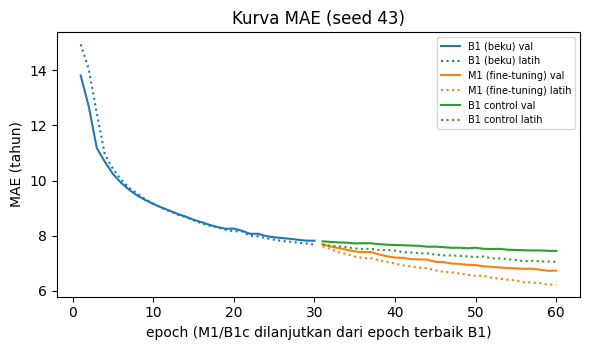

,best_val_mae,best_epoch,epochs_run,train_minutes,finished_utc
B1_s43,7.813,30,30,19.1,2026-10-12T13:05:36+00:00
M1_s43,6.716,29,30,19.8,2026-10-12T13:25:23+00:00
B1c_s43,7.441,30,30,20.2,2026-10-12T13:45:35+00:00


In [14]:
# @cell: curves
fig, axes = plt.subplots(1, len(CFG['SEEDS']), figsize=(6 * len(CFG['SEEDS']), 3.6), squeeze=False)
for k, seed in enumerate(CFG['SEEDS']):
    ax = axes[0, k]
    for (meth, s), rd in RUNS.items():
        if s != seed:
            continue
        h = pd.read_csv(rd / 'history.csv')
        offset = 0 if meth == 'B1' else int(json.load(open(RUNS[('B1', s)] / 'done.json'))['best_epoch'])
        l, = ax.plot(h.epoch + offset, h.val_mae, label=f'{METHOD_NAMES[meth]} val')
        ax.plot(h.epoch + offset, h.train_mae, ls=':', color=l.get_color(), label=f'{METHOD_NAMES[meth]} latih')
    ax.set(title=f'Kurva MAE (seed {seed})', xlabel='epoch (M1/B1c dilanjutkan dari epoch terbaik B1)', ylabel='MAE (tahun)')
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIRS['figures'] / 'kurva_mae.png', dpi=150); plt.show()
display(pd.DataFrame({f'{m}_s{s}': json.load(open(rd / 'done.json')) for (m, s), rd in RUNS.items()}).T)

## 6. Evaluasi
Selama `TEST_UNLOCKED = False`, semua tabel dan grafik di bawah dihitung pada **validasi** (`EVAL_SPLIT = 'val'`) untuk memilih konfigurasi dan ambang T. Setelah konfigurasi final ditetapkan, ubah ke `True` dan jalankan ulang bagian 6 sampai 8; hasil kemudian dihitung pada **data uji**. Waktu pembukaan data uji dicatat di Drive.

In [15]:
# @cell: unlock
TEST_UNLOCKED = False   # ubah ke True hanya setelah konfigurasi dan T dipilih dari validasi

EVAL_SPLIT = 'test' if TEST_UNLOCKED else 'val'
if TEST_UNLOCKED:
    lock = DIRS['results'] / 'test_unlock.json'
    if not lock.exists():
        json.dump({'unlocked_utc': now_utc(), 'manifest_sha256': MANIFEST_SHA,
                   'runs': [p.name for p in RUNS.values()]}, open(lock, 'w'), indent=1)
    print('Data uji dibuka:', json.load(open(lock)))

def split_df(name):
    if name == 'test' and not TEST_UNLOCKED:
        raise PermissionError('Data uji masih dikunci. Pilih konfigurasi dengan validasi, lalu set TEST_UNLOCKED = True.')
    return {'train': TR, 'val': VA, 'test': _TE}[name]

def get_preds(method, seed, split):
    """Prediksi mentah (tanpa pembulatan/pembatasan), di-cache sebagai CSV di Drive."""
    df = split_df(split)
    tag = 'B0' if method == 'B0' else run_dir(method, seed).name
    f = DIRS['results'] / 'preds' / f'{tag}_{split}_{MANIFEST_SHA[:8]}.csv'
    if f.exists():
        return pd.read_csv(f).pred.to_numpy()
    if method == 'B0':
        p = np.full(len(df), MEDIAN_AGE)
    else:
        ck = torch.load(run_dir(method, seed) / 'best.pt', map_location='cpu')
        m = build_model(ck['median_age'], pretrained=False)
        m.load_state_dict(ck['model'])
        p = predict(m, df)
    pd.DataFrame({'path': df.path, 'age': df.age, 'pred': p}).to_csv(f, index=False)
    return p

METHODS = ['B0', 'B1', 'M1', 'B1c'] + (['M1bal'] if CFG['RUN_BALANCED_SAMPLING'] else [])
SEED0 = CFG['SEEDS'][0]
EV = split_df(EVAL_SPLIT)
Y = EV.age.to_numpy().astype(float)
PRED = {m: get_preds(m, SEED0, EVAL_SPLIT) for m in METHODS}
print(f'Evaluasi pada split: {EVAL_SPLIT} (n = {len(EV)}), seed {SEED0}')

Evaluasi pada split: val (n = 3468), seed 43


In [16]:
# @cell: metrics
Z = {0.90: 1.645, 0.95: 1.96, 0.99: 2.576}[CFG['CI']]

def reg_metrics(y, p):
    e = p - y
    return {'n': len(y), 'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'MedAE': np.median(np.abs(e)), 'bias (pred-label)': np.mean(e)}

def wilson(k, n):
    if n == 0:
        return (np.nan, np.nan)
    ph = k / n; den = 1 + Z ** 2 / n
    c = (ph + Z ** 2 / (2 * n)) / den
    h = Z * np.sqrt(ph * (1 - ph) / n + Z ** 2 / (4 * n ** 2)) / den
    return (max(0.0, c - h), min(1.0, c + h))

def gate(y, p, L, T):
    minor, adult = y < L, y >= L
    fp, fn = int(((p >= T) & minor).sum()), int(((p < T) & adult).sum())
    nm, na = int(minor.sum()), int(adult.sum())
    return {'L': L, 'T': T, 'n<L': nm, 'n>=L': na,
            'FPR': fp / nm if nm else np.nan, 'FPR CI': wilson(fp, nm),
            'FNR': fn / na if na else np.nan, 'FNR CI': wilson(fn, na)}

def auc_at(y, p, L):
    lab = (y >= L).astype(int)
    return roc_auc_score(lab, p) if 0 < lab.sum() < len(lab) else np.nan

def recommend_T(method, L):
    """T terkecil dengan FPR validasi <= FPR_TARGET (dipilih HANYA dari validasi).
    Mengembalikan (T, tercapai); bila target tidak tercapai, T = batas atas pencarian."""
    yv, pv = VA.age.to_numpy().astype(float), get_preds(method, SEED0, 'val')
    for T_ in range(L, L + CFG['T_SEARCH_MAX_OFFSET'] + 1):
        if gate(yv, pv, L, T_)['FPR'] <= CFG['FPR_TARGET']:
            return T_, True
    return L + CFG['T_SEARCH_MAX_OFFSET'], False

SUMMARY = pd.DataFrame({METHOD_NAMES[m]: reg_metrics(Y, PRED[m]) for m in METHODS}).T
SUMMARY['penurunan MAE vs B0'] = 1 - SUMMARY.MAE / SUMMARY.loc[METHOD_NAMES['B0'], 'MAE']
print(f'Galat usia pada {EVAL_SPLIT} (tahun)')
display(SUMMARY)
SUMMARY.to_csv(DIRS['results'] / f'ringkasan_{EVAL_SPLIT}.csv')

Galat usia pada val (tahun)


,n,MAE,RMSE,MedAE,bias (pred-label),penurunan MAE vs B0
B0 (median),3468.0,14.410,19.919,9.000,-4.014,0.000
B1 (beku),3468.0,7.813,10.650,5.691,-0.539,0.458
M1 (fine-tuning),3468.0,6.716,9.381,4.766,-0.600,0.534
B1 control,3468.0,7.441,10.292,5.299,-0.481,0.484


MAE per kelompok usia (val)


,n,MAE B0,MAE B1,MAE M1,MAE B1c
age_bin,,,,,
0-12,487,24.774,7.314,5.043,6.469
13-17,112,13.607,10.679,9.135,10.315
18-24,353,7.221,5.670,5.114,5.562
25-39,1516,3.489,5.626,5.145,5.438
40-59,629,20.097,9.771,8.907,9.644
60+,371,42.873,15.254,12.413,14.092


MAE per jenis kelamin (val)


,n,MAE B0,MAE B1,MAE M1,MAE B1c
gender,,,,,
laki-laki,1862,15.461,7.817,6.741,7.470
perempuan,1606,13.192,7.808,6.688,7.409


MAE per ras (val)


,n,MAE B0,MAE B1,MAE M1,MAE B1c
race,,,,,
Asian,537,15.142,6.939,5.657,6.463
Black,685,9.342,7.326,6.728,7.202
Indian,589,13.299,7.744,6.745,7.254
Others,219,11.804,6.396,5.140,6.046
White,1438,17.403,8.614,7.334,8.210


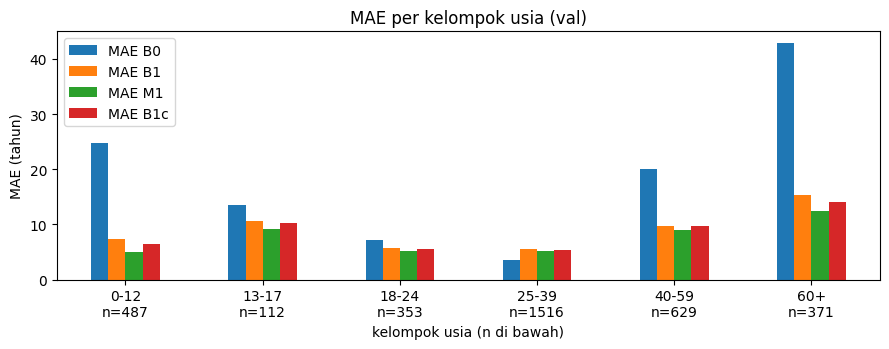

In [17]:
# @cell: groups
def by_group(col, mapping=None, order=None):
    rows = []
    keys = EV[col].map(mapping) if mapping else EV[col]
    for g in (order or sorted(keys.unique())):
        idx = (keys == g).to_numpy()
        row = {col: g, 'n': int(idx.sum())}
        for m in METHODS:
            row[f'MAE {m}'] = np.mean(np.abs(PRED[m][idx] - Y[idx])) if idx.any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index(col)

G_AGE = by_group('age_bin', order=BIN_LABELS)
G_SEX = by_group('gender', GENDER)
G_RACE = by_group('race', RACE)
for name, g in [('kelompok usia', G_AGE), ('jenis kelamin', G_SEX), ('ras', G_RACE)]:
    print(f'MAE per {name} ({EVAL_SPLIT})'); display(g)
    g.to_csv(DIRS['results'] / f"mae_per_{name.replace(' ', '_')}_{EVAL_SPLIT}.csv")

ax = G_AGE.drop(columns='n').plot.bar(figsize=(9, 3.6), rot=0)
ax.set(title=f'MAE per kelompok usia ({EVAL_SPLIT})', xlabel='kelompok usia (n di bawah)', ylabel='MAE (tahun)')
ax.set_xticklabels([f'{b}\nn={n}' for b, n in zip(G_AGE.index, G_AGE.n)])
plt.tight_layout(); plt.savefig(DIRS['figures'] / f'mae_per_kelompok_{EVAL_SPLIT}.png', dpi=150); plt.show()

Challenge-T pada val: FPR = di bawah L yang lolos (prediksi >= T); FNR = dewasa (>= L) yang terhambat. CI Wilson 95%. T rekomendasi: T terkecil dengan FPR validasi <= 0.05.


n<L  n>=L    FPR          FPR CI    FNR  \
metode           L  T                                             
B0 (median)      18 18  599  2869  1.000  [0.994, 1.000]  0.000   
                    21  599  2869  1.000  [0.994, 1.000]  0.000   
                    23  599  2869  1.000  [0.994, 1.000]  0.000   
                    30  599  2869  0.000  [0.000, 0.006]  1.000   
                 21 21  691  2777  1.000  [0.994, 1.000]  0.000   
                    24  691  2777  1.000  [0.994, 1.000]  0.000   
                    26  691  2777  1.000  [0.994, 1.000]  0.000   
                    30  691  2777  0.000  [0.000, 0.006]  1.000   
B1 (beku)        18 18  599  2869  0.324  [0.288, 0.362]  0.020   
                    21  599  2869  0.262  [0.228, 0.299]  0.053   
                    23  599  2869  0.220  [0.189, 0.255]  0.101   
                    33  599  2869  0.043  [0.030, 0.063]  0.507   
                 21 21  691  2777  0.330  [0.296, 0.366]  0.047   
                    24  691  2777  0.255  [0.224, 0.288]  0.125   
                    26  691  2777  0.188  [0.161, 0.219]  0.205   
                    34  691  2777  0.045  [0.032, 0.063]  0.530   
M1 (fine-tuning) 18 18  599  2869  0.257  [0.224, 0.294]  0.018   
                    21  599  2869  0.202  [0.172, 0.236]  0.044   
                    23  599  2869  0.159  [0.132, 0.190]  0.092   
                    31  599  2869  0.047  [0.033, 0.067]  0.460   
                 21 21  691  2777  0.274  [0.242, 0.308]  0.037   
                    24  691  2777  0.191  [0.163, 0.222]  0.117   
                    26  691  2777  0.143  [0.119, 0.171]  0.198   
                    32  691  2777  0.046  [0.033, 0.065]  0.482   
B1 control       18 18  599  2869  0.311  [0.275, 0.349]  0.020   
                    21  599  2869  0.254  [0.221, 0.290]  0.045   
                    23  599  2869  0.197  [0.167, 0.231]  0.089   
                    32  599  2869  0.048  [0.034, 0.069]  0.492   
                 21 21  691  2777  0.320  [0.286, 0.356]  0.038   
                    24  691  2777  0.240  [0.210, 0.273]  0.112   
                    26  691  2777  0.172  [0.146, 0.202]  0.202   
                    34  691  2777  0.041  [0.028, 0.058]  0.547   

                                FNR CI    AUC T rekomendasi (val)  
metode           L  T                                              
B0 (median)      18 18  [0.000, 0.001]  0.500                      
                    21  [0.000, 0.001]  0.500                      
                    23  [0.000, 0.001]  0.500                      
                    30  [0.999, 1.000]  0.500                  <-  
                 21 21  [0.000, 0.001]  0.500                      
                    24  [0.000, 0.001]  0.500                      
                    26  [0.000, 0.001]  0.500                      
                    30  [0.999, 1.000]  0.500                  <-  
B1 (beku)        18 18  [0.016, 0.026]  0.918                      
                    21  [0.045, 0.061]  0.918                      
                    23  [0.091, 0.113]  0.918                      
                    33  [0.489, 0.525]  0.918                  <-  
                 21 21  [0.040, 0.055]  0.902                      
                    24  [0.113, 0.138]  0.902                      
                    26  [0.190, 0.220]  0.902                      
                    34  [0.511, 0.549]  0.902                  <-  
M1 (fine-tuning) 18 18  [0.014, 0.023]  0.942                      
                    21  [0.037, 0.052]  0.942                      
                    23  [0.082, 0.104]  0.942                      
                    31  [0.442, 0.478]  0.942                  <-  
                 21 21  [0.031, 0.045]  0.925                      
                    24  [0.105, 0.129]  0.925                      
                    26  [0.184, 0.214]  0.925                      
                    32  [0.464, 0.501]  0.925

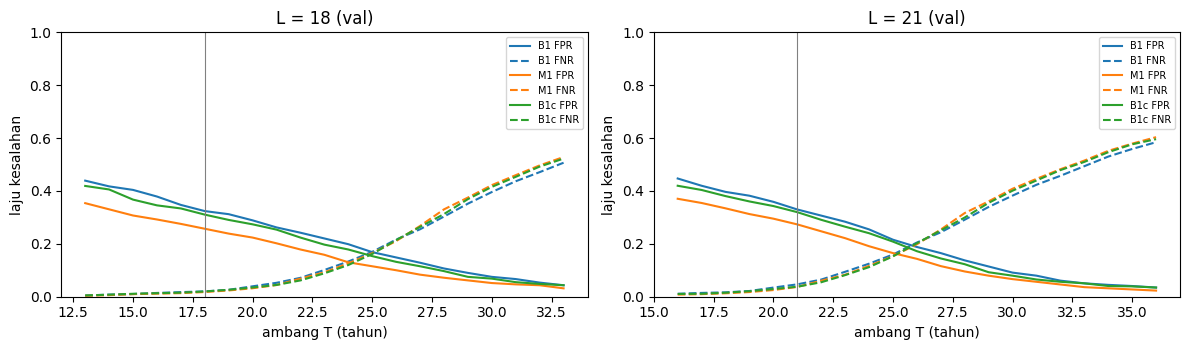

In [18]:
# @cell: gating
rows = []
T_REC = {}
for m in METHODS:
    for L in CFG['L_LIST']:
        T_REC[(m, L)], ok = recommend_T(m, L)
        Ts = sorted(set([L + o for o in CFG['T_OFFSETS']] + [T_REC[(m, L)]]))
        for T_ in Ts:
            r = gate(Y, PRED[m], L, T_)
            r.update({'metode': METHOD_NAMES[m], 'AUC': auc_at(Y, PRED[m], L),
                      'T rekomendasi (val)': ('<-' if ok else '<- target FPR tidak tercapai') if T_ == T_REC[(m, L)] else ''})
            rows.append(r)
GATE = pd.DataFrame(rows).set_index(['metode', 'L', 'T'])
fmt = lambda ci: f'[{ci[0]:.3f}, {ci[1]:.3f}]'
GATE['FPR CI'] = GATE['FPR CI'].map(fmt); GATE['FNR CI'] = GATE['FNR CI'].map(fmt)
print(f"Challenge-T pada {EVAL_SPLIT}: FPR = di bawah L yang lolos (prediksi >= T); FNR = dewasa (>= L) yang terhambat. "
      f"CI Wilson {int(CFG['CI'] * 100)}%. T rekomendasi: T terkecil dengan FPR validasi <= {CFG['FPR_TARGET']}.")
display(GATE)
GATE.to_csv(DIRS['results'] / f'challenge_T_{EVAL_SPLIT}.csv')

fig, axes = plt.subplots(1, len(CFG['L_LIST']), figsize=(6 * len(CFG['L_LIST']), 3.6), squeeze=False)
for k, L in enumerate(CFG['L_LIST']):
    ax = axes[0, k]
    Tgrid = np.arange(L - 5, L + CFG['T_SEARCH_MAX_OFFSET'] + 1)
    for m in [x for x in METHODS if x != 'B0']:
        g = [gate(Y, PRED[m], L, t) for t in Tgrid]
        l, = ax.plot(Tgrid, [r['FPR'] for r in g], label=f'{m} FPR')
        ax.plot(Tgrid, [r['FNR'] for r in g], ls='--', color=l.get_color(), label=f'{m} FNR')
    ax.axvline(L, color='grey', lw=0.8)
    ax.set(title=f'L = {L} ({EVAL_SPLIT})', xlabel='ambang T (tahun)', ylabel='laju kesalahan', ylim=(0, 1))
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(DIRS['figures'] / f'fpr_fnr_{EVAL_SPLIT}.png', dpi=150); plt.show()

In [19]:
# @cell: bootstrap
def paired_boot(a, b, seed=0):
    """Selisih MAE (a - b) dengan bootstrap berpasangan atas citra yang sama. Negatif = a lebih baik."""
    ea, eb = np.abs(PRED[a] - Y), np.abs(PRED[b] - Y)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(Y), size=(CFG['N_BOOT'], len(Y)))
    d = ea[idx].mean(1) - eb[idx].mean(1)
    lo, hi = np.percentile(d, [(1 - CFG['CI']) / 2 * 100, (1 + CFG['CI']) / 2 * 100])
    return {'pasangan': f'{a} - {b}', 'selisih MAE': ea.mean() - eb.mean(), 'CI bawah': lo, 'CI atas': hi,
            'CI memuat 0': bool(lo <= 0 <= hi)}

pairs = [('M1', 'B0'), ('M1', 'B1'), ('M1', 'B1c'), ('B1c', 'B1'), ('B1', 'B0')]
if 'M1bal' in METHODS:
    pairs.append(('M1bal', 'M1'))
BOOT = pd.DataFrame([paired_boot(a, b) for a, b in pairs]).set_index('pasangan')
print(f"Bootstrap berpasangan ({CFG['N_BOOT']} pengambilan ulang, CI {int(CFG['CI'] * 100)}%) pada {EVAL_SPLIT}")
display(BOOT)
BOOT.to_csv(DIRS['results'] / f'bootstrap_{EVAL_SPLIT}.csv')

Bootstrap berpasangan (1000 pengambilan ulang, CI 95%) pada val


,selisih MAE,CI bawah,CI atas,CI memuat 0
pasangan,,,,
M1 - B0,-7.694,-8.126,-7.281,False
M1 - B1,-1.096,-1.213,-0.985,False
M1 - B1c,-0.725,-0.812,-0.634,False
B1c - B1,-0.371,-0.432,-0.319,False
B1 - B0,-6.597,-7.037,-6.195,False


In [20]:
# @cell: seeds
if len(CFG['SEEDS']) > 1:
    rows = []
    for m in [x for x in METHODS if x != 'B0']:
        maes = [np.mean(np.abs(get_preds(m, s, EVAL_SPLIT) - Y)) for s in CFG['SEEDS']]
        rows.append({'metode': METHOD_NAMES[m], 'MAE rerata': np.mean(maes), 'SD': np.std(maes, ddof=1),
                     'per seed': np.round(maes, 3).tolist()})
    SEEDTAB = pd.DataFrame(rows).set_index('metode')
    display(SEEDTAB); SEEDTAB.to_csv(DIRS['results'] / f'antar_seed_{EVAL_SPLIT}.csv')
else:
    print('Satu seed: keterbatasan ini dinyatakan dalam laporan.')

Satu seed: keterbatasan ini dinyatakan dalam laporan.


## 7. Analisis galat
Grafik prediksi terhadap label, histogram residual, dan contoh dengan galat tertinggi (M1). Pengamatan visual dicatat sebagai hipotesis penyebab, bukan bukti.

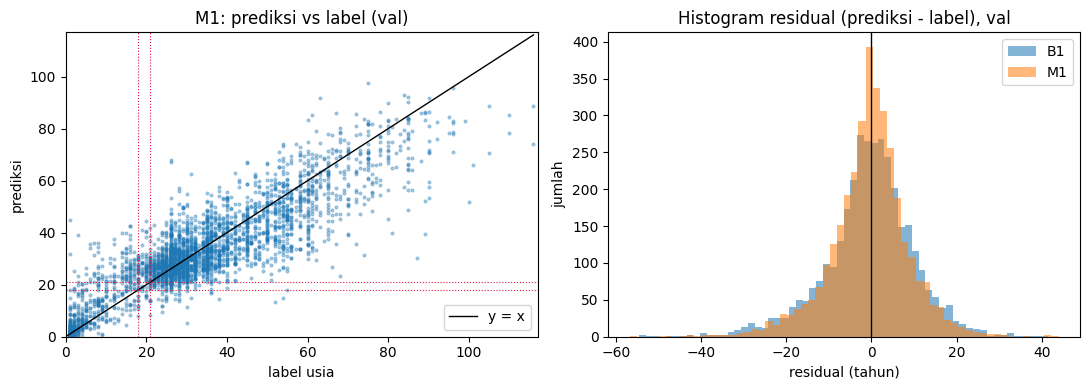

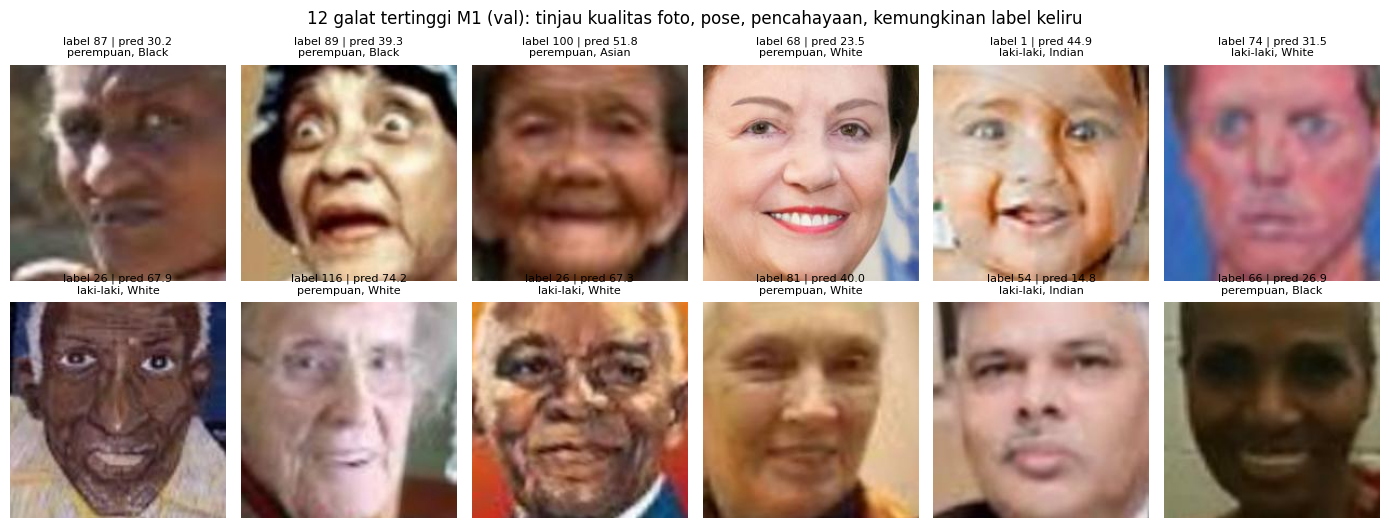

In [21]:
# @cell: errors
p = PRED['M1']
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(Y, p, s=4, alpha=0.35)
ax[0].plot([0, 116], [0, 116], color='k', lw=1, label='y = x')
for L in CFG['L_LIST']:
    ax[0].axvline(L, color='crimson', ls=':', lw=0.8); ax[0].axhline(L, color='crimson', ls=':', lw=0.8)
ax[0].set(title=f'M1: prediksi vs label ({EVAL_SPLIT})', xlabel='label usia', ylabel='prediksi', xlim=(0, 117), ylim=(0, 117))
ax[0].legend()
for m in ['B1', 'M1']:
    ax[1].hist(PRED[m] - Y, bins=60, alpha=0.55, label=m)
ax[1].axvline(0, color='k', lw=1)
ax[1].set(title=f'Histogram residual (prediksi - label), {EVAL_SPLIT}', xlabel='residual (tahun)', ylabel='jumlah')
ax[1].legend(); plt.tight_layout()
plt.savefig(DIRS['figures'] / f'prediksi_residual_{EVAL_SPLIT}.png', dpi=150); plt.show()

err = pd.DataFrame({'path': EV.path, 'age': EV.age, 'gender': EV.gender.map(GENDER), 'race': EV.race.map(RACE),
                    'pred': p, 'abs_err': np.abs(p - Y)}).sort_values('abs_err', ascending=False)
err.head(50).to_csv(DIRS['results'] / f'galat_tertinggi_M1_{EVAL_SPLIT}.csv', index=False)
top = err.head(12)
fig, axes = plt.subplots(2, 6, figsize=(14, 5.4))
for ax, (_, r) in zip(axes.ravel(), top.iterrows()):
    ax.imshow(Image.open(LOCAL / r.path).convert('RGB')); ax.axis('off')
    ax.set_title(f'label {r.age} | pred {r.pred:.1f}\n{r.gender}, {r.race}', fontsize=8)
plt.suptitle(f'12 galat tertinggi M1 ({EVAL_SPLIT}): tinjau kualitas foto, pose, pencahayaan, kemungkinan label keliru')
plt.tight_layout(); plt.savefig(DIRS['figures'] / f'galat_tertinggi_{EVAL_SPLIT}.png', dpi=150); plt.show()

## 8. Biaya komputasi
Parameter, MAdds (dihitung dengan *hook* pada Conv2d dan Linear), ukuran berkas, dan latensi CPU *batch* 1 setelah pemanasan (median dan persentil ke-95). Waktu praproses dan inferensi dipisahkan. Latensi CPU Colab hanya proksi bagi perangkat *edge*.

In [22]:
# @cell: efficiency
def count_macs(model, size=224):
    macs = 0
    def conv(mod, inp, out):
        nonlocal macs
        macs += out[0].numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0] * mod.kernel_size[1]
    def lin(mod, inp, out):
        nonlocal macs
        macs += mod.in_features * mod.out_features
    hooks = [x.register_forward_hook(conv) for x in model.modules() if isinstance(x, nn.Conv2d)]
    hooks += [x.register_forward_hook(lin) for x in model.modules() if isinstance(x, nn.Linear)]
    model.eval()
    with torch.inference_mode():
        model(torch.zeros(1, 3, size, size))
    for h in hooks:
        h.remove()
    return macs

def file_mb(model):
    f = Path('/tmp/_size.pt'); torch.save(model.state_dict(), f)
    return f.stat().st_size / 1e6

ck = torch.load(run_dir('M1', SEED0) / 'best.pt', map_location='cpu')
cpu_model = build_model(ck['median_age'], pretrained=False); cpu_model.load_state_dict(ck['model']); cpu_model.eval()
ref = models.mobilenet_v3_small(weights=None).eval()   # konfigurasi ImageNet 1000 kelas sebagai pembanding

lat_imgs = [LOCAL / p for p in VA.path.sample(min(CFG['LAT_PREPROC_RUNS'], len(VA)), random_state=0)]
pre_ms = []
for f in lat_imgs:
    t0 = time.perf_counter()
    with Image.open(f) as im:
        x = TF_EVAL(im.convert('RGB')).unsqueeze(0)
    pre_ms.append((time.perf_counter() - t0) * 1000)

inf_ms = []
with torch.inference_mode():
    for _ in range(CFG['LAT_WARMUP']):
        cpu_model(x)
    for _ in range(CFG['LAT_RUNS']):
        t0 = time.perf_counter(); cpu_model(x); inf_ms.append((time.perf_counter() - t0) * 1000)

EFF = {
    'parameter (model regresi)': sum(p.numel() for p in cpu_model.parameters()),
    'parameter (MobileNetV3-Small 1000 kelas)': sum(p.numel() for p in ref.parameters()),
    'MAdds (model regresi, juta)': count_macs(cpu_model) / 1e6,
    'MAdds (1000 kelas, juta)': count_macs(ref) / 1e6,
    'ukuran berkas FP32 (MB)': file_mb(cpu_model),
    'praproses median (ms)': float(np.median(pre_ms)), 'praproses p95 (ms)': float(np.percentile(pre_ms, 95)),
    'inferensi median (ms)': float(np.median(inf_ms)), 'inferensi p95 (ms)': float(np.percentile(inf_ms, 95)),
    'pengulangan inferensi': CFG['LAT_RUNS'], 'thread CPU': torch.get_num_threads(), 'CPU': ENV['cpu'],
}
display(pd.Series(EFF, name='nilai').to_frame())
json.dump(EFF, open(DIRS['results'] / 'efisiensi.json', 'w'), indent=1, default=float)

,nilai
parameter (model regresi),1518881
parameter (MobileNetV3-Small 1000 kelas),2542856
"MAdds (model regresi, juta)",55.487
"MAdds (1000 kelas, juta)",56.51
ukuran berkas FP32 (MB),6.195
praproses median (ms),1.954
praproses p95 (ms),2.14
inferensi median (ms),10.011
inferensi p95 (ms),13.109
pengulangan inferensi,2000


In [23]:
# @cell: criteria
if not TEST_UNLOCKED:
    print('Ukuran keberhasilan (Bagian 1.6) hanya dinilai pada data uji. Buka data uji di bagian 6 terlebih dulu.')
else:
    red = SUMMARY.loc[METHOD_NAMES['M1'], 'penurunan MAE vs B0']
    b = BOOT.loc['M1 - B1c']
    auc_rows = {L: (auc_at(Y, PRED['M1'], L), auc_at(Y, PRED['B1c'], L)) for L in CFG['L_LIST']}
    crit = [
        ('(1) MAE M1 turun >= {:.0%} vs B0'.format(CFG['MAE_REDUCTION_TARGET']), f'{red:.1%}', red >= CFG['MAE_REDUCTION_TARGET']),
        ('(2) MAE M1 < B1 control, CI selisih tidak memuat 0', f"{b['selisih MAE']:.3f} [{b['CI bawah']:.3f}, {b['CI atas']:.3f}]",
         bool(b['selisih MAE'] < 0 and not b['CI memuat 0'])),
    ] + [(f'(3) AUC M1 > B1 control pada L = {L}', f'{a1:.3f} vs {a2:.3f}', bool(a1 > a2)) for L, (a1, a2) in auc_rows.items()] + [
        ('(4) latensi inferensi CPU median <= {:.0f} ms'.format(CFG['LAT_TARGET_MS']), f"{EFF['inferensi median (ms)']:.1f} ms",
         EFF['inferensi median (ms)'] <= CFG['LAT_TARGET_MS']),
        ('(5) reproduksi: manifest, seed, notebook tercatat', f'manifest {MANIFEST_SHA[:12]}..., seed {CFG["SEEDS"]}', True),
    ]
    CRIT = pd.DataFrame(crit, columns=['kriteria', 'nilai', 'terpenuhi']).set_index('kriteria')
    display(CRIT); CRIT.to_csv(DIRS['results'] / 'ukuran_keberhasilan.csv')
    json.dump({'manifest_sha256': MANIFEST_SHA, 'seeds': CFG['SEEDS'], 'run_tag': CFG['RUN_TAG'],
               'summary_test': SUMMARY.to_dict(), 'T_rekomendasi': {f'{m}_L{L}': t for (m, L), t in T_REC.items()},
               'efisiensi': EFF, 'env': ENV, 'created_utc': now_utc()},
              open(DIRS['results'] / 'ringkasan_akhir.json', 'w'), indent=1, default=float)

Ukuran keberhasilan (Bagian 1.6) hanya dinilai pada data uji. Buka data uji di bagian 6 terlebih dulu.


## 9. Demo inferensi
Unggah satu citra wajah JPG/PNG yang **sudah dipotong** dan penggunaannya disetujui pemiliknya. Citra diproses di memori dan tidak disalin ke Drive. Prediksi mentah dibedakan dari nilai tampilan yang dibulatkan. Keputusan memakai kebijakan *Challenge-T* dengan T rekomendasi dari validasi.

Saving WhatsApp Image 2026-10-12 at 20.50.41.jpeg to WhatsApp Image 2026-10-12 at 20.50.41.jpeg


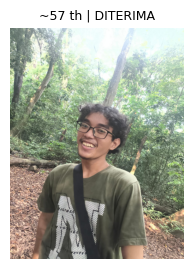

WhatsApp Image 2026-10-12 at 20.50.41.jpeg: prediksi mentah 56.56 th (tampilan 57 th) | L = 18, T = 31 -> DITERIMA
  praproses 45.5 ms | inferensi CPU 13.5 ms


In [24]:
# @cell: demo
DEMO_L = 18
T_demo, _ = recommend_T('M1', DEMO_L)
if 'cpu_model' not in globals():
    ck = torch.load(run_dir('M1', SEED0) / 'best.pt', map_location='cpu')
    cpu_model = build_model(ck['median_age'], pretrained=False); cpu_model.load_state_dict(ck['model']); cpu_model.eval()
if IN_COLAB:
    from google.colab import files
    up = files.upload()
    for name, data in up.items():
        t0 = time.perf_counter()
        with Image.open(io.BytesIO(data)) as im:
            img = im.convert('RGB')
        x = TF_EVAL(img).unsqueeze(0)
        t1 = time.perf_counter()
        with torch.inference_mode():
            raw = float(cpu_model(x).squeeze())
        t2 = time.perf_counter()
        shown = int(round(min(max(raw, CFG['AGE_RANGE'][0]), CFG['AGE_RANGE'][1])))
        decision = 'DITERIMA' if raw >= T_demo else 'PERLU VERIFIKASI TAMBAHAN'
        plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis('off')
        plt.title(f'~{shown} th | {decision}', fontsize=9); plt.show()
        print(f'{name}: prediksi mentah {raw:.2f} th (tampilan {shown} th) | L = {DEMO_L}, T = {T_demo} -> {decision}')
        print(f'  praproses {1000 * (t1 - t0):.1f} ms | inferensi CPU {1000 * (t2 - t1):.1f} ms')
        del data, img
else:
    print('Demo unggah hanya tersedia di Colab.')

## Catatan untuk Bab 3
Semua tabel (`results/*.csv`), gambar (`figures/*.png`), dan ringkasan (`results/ringkasan_akhir.json`) tersimpan di Drive dengan akhiran `_val` atau `_test`. Laporkan angka **test** hanya dari run setelah `TEST_UNLOCKED = True`; angka validasi dipakai untuk menjelaskan pemilihan konfigurasi dan T. Sertakan juga `manifest/meta.json` (jumlah citra, alasan pengeluaran, pasangan mirip) dan `env_*.json` (perangkat dan versi pustaka).